### Who is leaving, what it costs and who should get a retention offer
**Tools:** Python, pandas, Matplotlib, seaborn, scikit-learn


## 1. The business problem
**Context.** A telecom company sells phone and internet subscriptions. Customers pay every month, so the company only earns money for as long as a customer stays. When a customer cancels (churns), that monthly income stops and winning a new customer to replace them usually costs more than keeping the old one.

**The problem.** The company knows that many customers are leaving, but not which customers or why. The retention team has a limited budget. It cannot call every customer or give everyone a discount, so today its offers are not targeted.

The questions this analysis answers:
- How many customers leave and how much revenue goes with them? (Section 5 and 6)
- Which kinds of customers leave most often? (Section 5 and 6)
- Can we tell in advance which customers are at risk?	(Section 7)
- Who should get a retention offer and is it worth the money?	(Section 8)

**Who this is for.** The retention and marketing team (who to contact), product managers (what to fix) and finance (what it is worth).

**What success looks like.** A short list of clear churn drivers, a ranked list of at-risk customers the retention team can use and an estimate of the campaign's profit with its assumptions stated openly.



## 2. The dataset

**Source.** The [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) dataset, a sample dataset published by IBM and widely used for practising churn analysis. The company is fictional.

**Shape.** 7,043 rows and 21 columns. **Each row is one customer.** The data is a single snapshot: it shows each customer's details and whether they left within the last month.

**Dataset Dictionary**

| Category | Feature | Description |
|---|---|---|
| **Identification** | `customerID` | Unique customer identifier |
| **Target** | `Churn` | Whether the customer left the company in the last month (Yes/No) |
| **Demographics** | `gender` | Male/Female |
| | `SeniorCitizen` | Whether the customer is aged 65 or older (1/0) |
| | `Partner` | Whether the customer has a partner (Yes/No) |
| | `Dependents` | Whether the customer has dependents, such as children (Yes/No) |
| **Account** | `tenure` | Number of months the customer has been with the company |
| | `Contract` | Contract type: Month-to-month, One year, Two year |
| | `PaperlessBilling` | Gets bills by email (Yes/No) |
| | `PaymentMethod` | Electronic check, Mailed check, Bank transfer (automatic), Credit card (automatic) |
| | `MonthlyCharges` | Current monthly bill |
| | `TotalCharges` | Total amount billed so far |
| **Services** | `PhoneService` | Has a phone line (Yes / No) |
| | `MultipleLines` | Has more than one phone line |
| | `InternetService` | Internet connection type: DSL, Fiber optic, None |
| | `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport` | Internet add-ons (Yes / No / No internet service) |
| | `StreamingTV`, `StreamingMovies` | Streaming add-ons (Yes / No / No internet service) |

## 3. Setup and loading the data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MultipleLocator, PercentFormatter
from scipy.stats import chi2_contingency

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DATA_FILE = Path('data/WA_Fn-UseC_-Telco-Customer-Churn.csv')

FIG_DIR = Path('figures')
OUT_DIR = Path('outputs')

FIG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

SEED = 42  
pd.set_option('display.max_columns', 30)

**Consistent colour scheme for all charts.**


In [2]:
# Plain matplotlib defaults with basic colours
STAYED = 'tab:blue'
LEFT = 'red'
GREY = 'grey'

INK = 'black'
INK_2 = 'black'
SURFACE = 'white'

BLUES = 'Blues'
DIVERGING = 'RdBu'   # red = negative, blue = positive

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160, 'savefig.bbox': 'tight'})


def save(name):
    plt.savefig(FIG_DIR / f'{name}.png')
    plt.show()

In [3]:
raw = pd.read_csv(DATA_FILE)
print(f'{raw.shape[0]:,} rows and {raw.shape[1]} columns')
raw.head()

7,043 rows and 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# 4. Data quality and cleaning

Right data types, no duplicate customers, no missing values and no strange category labels.

### 4.1 Data types and missing values

In [4]:
overview = pd.DataFrame({
    'Data type': raw.dtypes.astype(str),
    'Missing values': raw.isna().sum(),
    'Unique values': raw.nunique(),
    'Example': raw.iloc[0],
})
overview

,Data type,Missing values,Unique values,Example
customerID,object,0,7043,7590-VHVEG
gender,object,0,2,Female
SeniorCitizen,int64,0,2,0
Partner,object,0,2,Yes
Dependents,object,0,2,No
tenure,int64,0,73,1
PhoneService,object,0,2,No
MultipleLines,object,0,3,No phone service
InternetService,object,0,3,DSL
OnlineSecurity,object,0,3,No


Two things stand out:

- **`TotalCharges` is stored as text** (`object`) although it is a dollar amount. It needs to be converted to a number.
- **`SeniorCitizen` is stored as 0 / 1** while every other yes/no column uses the words Yes / No. I will make it consistent.

### 4.2 Duplicates

In [5]:
print('Fully duplicated rows:', raw.duplicated().sum())
print('Repeated customer IDs:', raw['customerID'].duplicated().sum())

Fully duplicated rows: 0
Repeated customer IDs: 0


### 4.3 Investigating `TotalCharges` problem

In [6]:
raw['TotalCharges'].map(type).value_counts() #actual data type

TotalCharges
<class 'str'>    7043
Name: count, dtype: int64

In [7]:
(raw['TotalCharges'].astype(str).str.strip() == '').sum() #empty strings

11

Converting `TotalCharges` to a number shows why it was stored as text: a few rows contain a blank space instead of a value.

In [8]:
df = raw.copy()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')  # blanks become NaN

blank = df['TotalCharges'].isna()
print('Rows with a blank TotalCharges:', blank.sum())
df.loc[blank, ['customerID', 'tenure', 'Contract', 'MonthlyCharges', 'TotalCharges', 'Churn']]

Rows with a blank TotalCharges: 11


,customerID,tenure,Contract,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,Two year,52.55,NaN,No
753,3115-CZMZD,0,Two year,20.25,NaN,No
936,5709-LVOEQ,0,Two year,80.85,NaN,No
1082,4367-NUYAO,0,Two year,25.75,NaN,No
1340,1371-DWPAZ,0,Two year,56.05,NaN,No
3331,7644-OMVMY,0,Two year,19.85,NaN,No
3826,3213-VVOLG,0,Two year,25.35,NaN,No
4380,2520-SGTTA,0,Two year,20.00,NaN,No
5218,2923-ARZLG,0,One year,19.70,NaN,No
6670,4075-WKNIU,0,Two year,73.35,NaN,No


All 11 customers have tenure = 0. They are brand-new customers who have not received their first bill yet, so the blank is not an error. Their real total so far is $0, so I fill the blanks with 0 instead of deleting the rows.

### 4.4 Cleaning steps

In [9]:
# 1. New customers have been billed nothing so far
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# 2. SeniorCitizen = yes/no 
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

# 3. A numeric version of the target: 1 = left, 0 = stayed (its average is the churn rate)
df['Churned'] = (df['Churn'] == 'Yes').astype(int)

# 4. Tenure into bands 
df['TenureGroup'] = pd.cut(
    df['tenure'], bins=[-1, 6, 12, 24, 48, 72],
    labels=['0-6 months', '7-12 months', '13-24 months', '25-48 months', '49-72 months'],
)

print('Missing values left:', df.isna().sum().sum())
print('Rows:', len(df))

Missing values left: 0
Rows: 7043


### 4.5 Category labels 

A quick look at every category column, to catch typos or labels written in two different ways.

In [10]:
category_columns = [c for c in raw.columns if raw[c].dtype == 'object' and c not in ('customerID', 'TotalCharges')]
category_columns.insert(1, 'SeniorCitizen')

pd.DataFrame({'Values': [', '.join(sorted(df[c].unique())) for c in category_columns]}, index=category_columns)

,Values
gender,"Female, Male"
SeniorCitizen,"No, Yes"
Partner,"No, Yes"
Dependents,"No, Yes"
PhoneService,"No, Yes"
MultipleLines,"No, No phone service, Yes"
InternetService,"DSL, Fiber optic, No"
OnlineSecurity,"No, No internet service, Yes"
OnlineBackup,"No, No internet service, Yes"
DeviceProtection,"No, No internet service, Yes"


**Data quality summary**

- Duplicate rows or customer IDs = None
- Missing values = 11 blank `TotalCharges`, all new customers, set to 0
- Wrong data types = `TotalCharges` converted from text to number
- Inconsistent labels = `SeniorCitizen` changed from 0 / 1 to No / Yes. No typos found 
- Rows removed = None. All 7,043 customers are kept 

The labels "No internet service" and "No phone service" are not errors. They mean the customer could not have that add-on because they do not buy the main service.

## 5. Exploratory data analysis (EDA)

How many customers left, what the numeric columns look like and how the churn rate changes from group to group.

### 5.1 How many customers left?

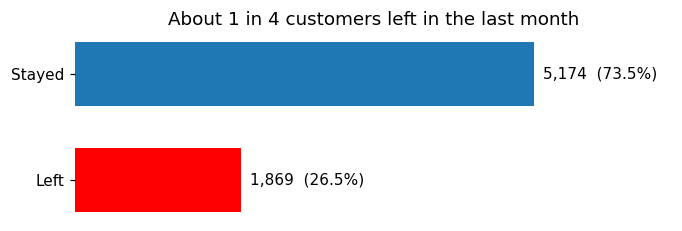

In [11]:
counts = df['Churn'].value_counts()
churn_rate = df['Churned'].mean()

fig, ax = plt.subplots(figsize=(7, 2.2))
bars = ax.barh(['Stayed', 'Left'], [counts['No'], counts['Yes']], color=[STAYED, LEFT], height=0.6)
ax.bar_label(bars, labels=[f"{counts['No']:,}  ({1 - churn_rate:.1%})", f"{counts['Yes']:,}  ({churn_rate:.1%})"], padding=6)
ax.invert_yaxis()
ax.set_xlim(0, counts['No'] * 1.3)
ax.xaxis.set_visible(False)
ax.spines[:].set_visible(False)
ax.set_title('About 1 in 4 customers left in the last month')
save('01_churn_overview')

 **Insight:** **1,869 customers (26.5%) left** and 5,174 (73.5%) stayed. The two groups are not the same size. This matters later: a model that simply says "nobody leaves" would be right 73.5% of the time and still be useless, so accuracy alone is not a good way to judge a model here.

### 5.2 The numeric columns

In [12]:
NUMERIC = ['tenure', 'MonthlyCharges', 'TotalCharges']
df[NUMERIC].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.4,24.6,0.0,9.0,29.0,55.0,72.0
MonthlyCharges,7043.0,64.8,30.1,18.2,35.5,70.4,89.8,118.8
TotalCharges,7043.0,2279.7,2266.8,0.0,398.6,1394.6,3786.6,8684.8


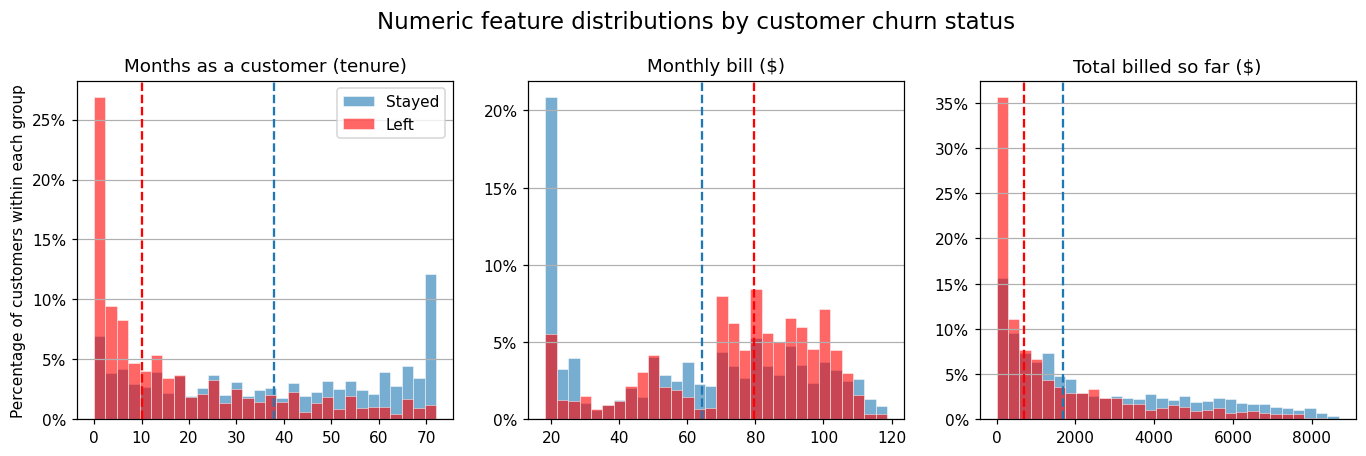

,tenure,MonthlyCharges,TotalCharges
Churn,,,
Stayed (median),38.0,64.425,1679.525
Left (median),10.0,79.650,703.550


In [13]:
titles = {'tenure': 'Months as a customer (tenure)', 'MonthlyCharges': 'Monthly bill ($)', 'TotalCharges': 'Total billed so far ($)'}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, NUMERIC):
    bins = np.linspace(df[column].min(), df[column].max(), 31)
    for value, label, colour in [(0, 'Stayed', STAYED), (1, 'Left', LEFT)]:
        data = df.loc[df['Churned'] == value, column]
        ax.hist(data, bins=bins, weights=np.ones(len(data)) / len(data), color=colour, alpha=0.6,
                label=label, edgecolor=SURFACE, linewidth=0.5)
        ax.axvline(data.median(), color=colour, linestyle='--', linewidth=1.5)
    ax.yaxis.set_major_locator(MultipleLocator(0.05))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis='y')
    ax.set_title(titles[column])
axes[0].set_ylabel('Percentage of customers within each group')
axes[0].legend()
fig.suptitle('Numeric feature distributions by customer churn status', fontsize=15, y=1.04)
save('02_numeric_distributions')

df.groupby('Churn')[NUMERIC].median().rename(index={'No': 'Stayed (median)', 'Yes': 'Left (median)'})

In [14]:
cheap = df[df['MonthlyCharges'].between(18, 25)]

print('Customers:', len(cheap))
print('Churn rate:', round(cheap['Churned'].mean() * 100, 1), '%')
print(cheap['Churn'].value_counts())

Customers: 1406
Churn rate: 9.0 %
Churn
No     1279
Yes     127
Name: count, dtype: int64


In [15]:
print('Overall churn rate:', round(df['Churned'].mean() * 100, 1), '%')

Overall churn rate: 26.5 %


 **Insight:**
 - **Tenure:** leavers are much newer. Their median tenure is **10 months**, against **38 months** for those who stayed. Leaving is most common right at the start.
 - **Monthly bill:** cheaper-plan customers left less frequently in this dataset.Leavers pay more, a median of about 80 against 64. Customers paying 18–25 per month had a lower churn rate (9%) than the overall customer base (26.5%).
 - **Total billed:** Customers who left had lower total payments, mainly because they had been with the company for fewer months. This overlaps with the tenure finding, since longer-term customers generally accumulate higher total charges (see 5.5).

### 5.3 Churn rate by customer group

For each category column, the chart shows the **percentage of customers in each group who left**. The grey dashed line is the company average (26.5%), so a bar far to the right of the line is a high-risk group.

In [16]:
def get_churn_rates(column):
    result = df.groupby(column, observed=True)['Churned'].agg(
        churn_rate='mean',
        customers='size'
    )
    return result.sort_values('churn_rate', ascending=False)


def plot_churn_rates(ax, column):
    result = get_churn_rates(column)

    bars = ax.barh(
        result.index.astype(str),
        result['churn_rate'],
        color=LEFT,
        height=0.62
    )

    labels = [
        f'{rate:.0%} (n={count:,})'
        for rate, count in zip(result['churn_rate'], result['customers'])
    ]

    ax.bar_label(bars, labels=labels, padding=4, fontsize=9)

    ax.axvline(churn_rate, color=GREY, linestyle='--', linewidth=1.2)
    ax.invert_yaxis()
    ax.set_xlim(0, 0.75)
    ax.xaxis.set_visible(False)
    ax.spines[:].set_visible(False)
    ax.set_title(column, fontsize=12)

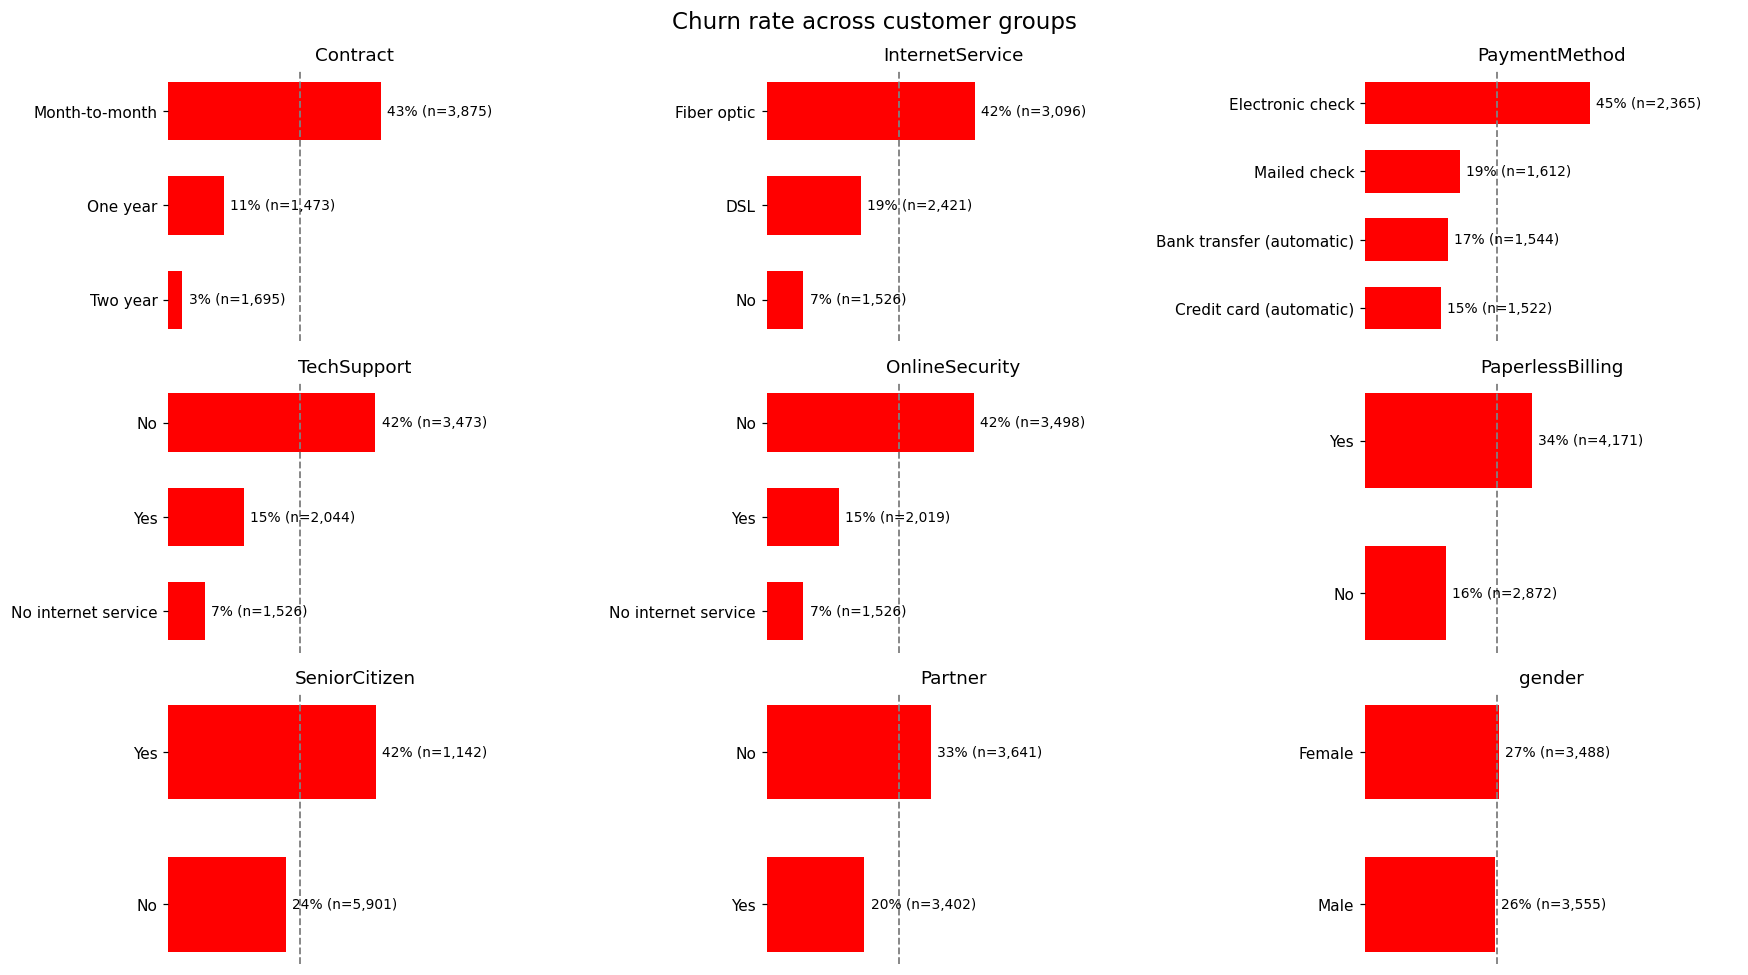

In [17]:
panels = [
    'Contract', 'InternetService', 'PaymentMethod',
    'TechSupport', 'OnlineSecurity', 'PaperlessBilling',
    'SeniorCitizen', 'Partner', 'gender'
]

fig, axes = plt.subplots(3, 3, figsize=(16, 9))

for ax, column in zip(axes.flat, panels):
    plot_churn_rates(ax, column)

fig.suptitle(
    'Churn rate across customer groups',
    fontsize=15
)

fig.tight_layout()
save('03_churn_by_group')

 **Insight:**
 - **Contract** shows the biggest gap: **43%** of month-to-month customers left, against 11% on one-year and only **3%** on two-year contracts.
 - **Fiber optic** internet customers leave at **42%**, more than twice the rate of DSL customers (19%).
 - Customers who pay by **electronic check** leave at **45%**. The other three payment methods are all between 15% and 19%.
 - Customers **without tech support or online security** leave at about 42%, against 15% for those who have them.
 - **Senior citizens** leave more often (42% against 24%), and customers with a partner leave less.
 - **Gender makes no difference** (27% and 26%).
 
 
Customer churn is associated more strongly with service and contract characteristics than with basic demographics. Month-to-month contracts, electronic check payments, fiber optic internet and the absence of technical support or online security are associated with higher churn rates. Senior citizens also show higher churn, while gender has almost no relationship with churn.

### 5.4 Churn rate by time as a customer

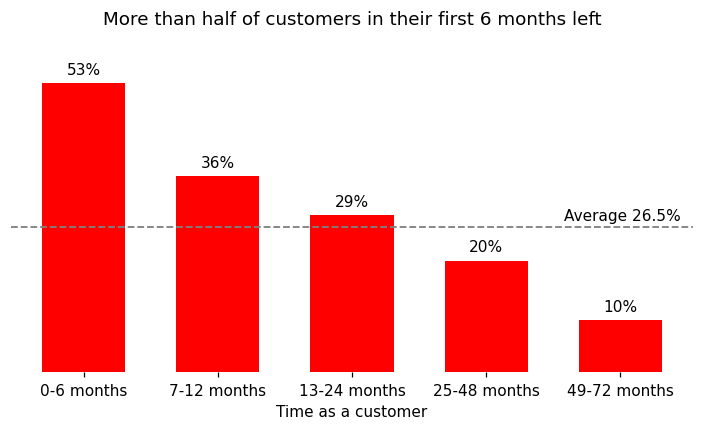

In [18]:
table = get_churn_rates('TenureGroup').sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(table.index.astype(str), table['churn_rate'], color=LEFT, width=0.62)
ax.bar_label(bars, labels=[f'{r:.0%}' for r in table['churn_rate']], padding=4)
ax.axhline(churn_rate, color=GREY, linestyle='--', linewidth=1.2)
ax.text(4.45, churn_rate + 0.012, f'Average {churn_rate:.1%}', color=INK_2, ha='right', fontsize=10)
ax.set_ylim(0, 0.62)
ax.yaxis.set_visible(False)
ax.spines[:].set_visible(False)
ax.set_xlabel('Time as a customer')
ax.set_title('More than half of customers in their first 6 months left')
save('04_churn_by_tenure')

**Insight:** the risk of leaving falls with time. **53%** of customers in their first 6 months left, against **10%** of those who have been customers for more than 4 years. The first year is the critical period.

### 5.5 Do the numeric columns overlap?

A correlation of +1 means two columns rise together, -1 means one rises as the other falls and 0 means no straight-line link.

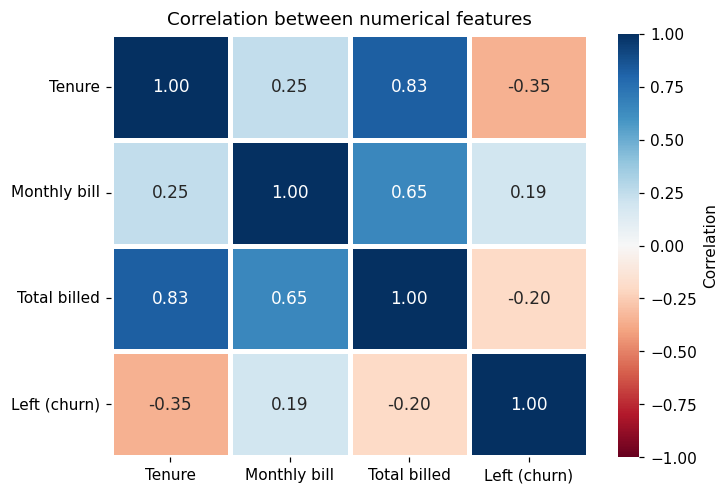

In [19]:
corr = df[NUMERIC + ['Churned']].corr()

corr.index = corr.columns = [
    'Tenure', 'Monthly bill', 'Total billed', 'Left (churn)'
]

fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 11},
    cmap=DIVERGING,
    vmin=-1,
    vmax=1,
    linewidths=2,
    cbar_kws={'label': 'Correlation'},
    ax=ax
)

ax.set_title('Correlation between numerical features')
ax.tick_params(axis='x', rotation=0)
ax.tick_params(axis='y', rotation=0)

save('05_correlation')

In [20]:
print(corr)

                Tenure  Monthly bill  Total billed  Left (churn)
Tenure        1.000000      0.247900      0.826178     -0.352229
Monthly bill  0.247900      1.000000      0.651174      0.193356
Total billed  0.826178      0.651174      1.000000     -0.198324
Left (churn) -0.352229      0.193356     -0.198324      1.000000


 **Insight:** `TotalCharges` is strongly linked to `tenure` (**0.83**), which makes sense because it is roughly *months × monthly bill*. It adds little new information, so I leave it out of the model in section 7. Of the three, **tenure has the strongest link to churn (-0.35)**: the longer someone has been a customer, the less likely they are to leave.

### 5.6 Which columns matter most?

The charts so far look at one column at a time. To rank all the category columns on one scale I use **Cramér's V**, a number from 0 (no link with churn) to 1 (a perfect link).

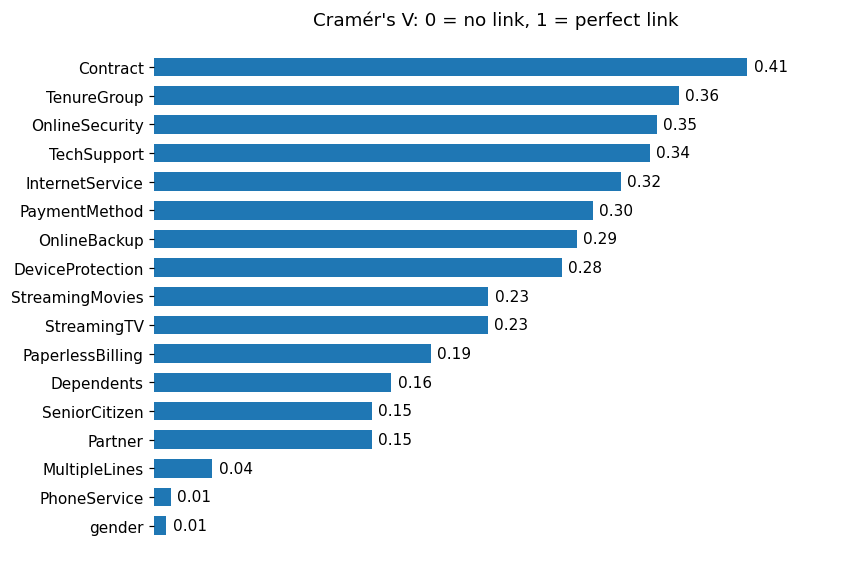

In [21]:
def cramers_v(column):
    table = pd.crosstab(df[column], df['Churned'])
    chi2 = chi2_contingency(table)[0]
    return np.sqrt(chi2 / (len(df) * (min(table.shape) - 1)))


strength = pd.Series({c: cramers_v(c) for c in category_columns + ['TenureGroup'] if c != 'Churn'}).sort_values()

fig, ax = plt.subplots(figsize=(8, 6.2))
bars = ax.barh(strength.index, strength.values, color=STAYED, height=0.65)
ax.bar_label(bars, fmt='%.2f', padding=4, fontsize=10)
ax.set_xlim(0, strength.max() * 1.15)
ax.xaxis.set_visible(False)
ax.spines[:].set_visible(False)
ax.set_title("Cramér's V: 0 = no link, 1 = perfect link")
save('06_factor_strength')

 **Insight:** **contract type (0.41)** and **time as a customer (0.36)** are the strongest factors, followed by online security, tech support and internet type. 
 **Gender and phone service are at 0.01**, which means they tell us nothing about who leaves.

### EDA takeaways

1. **26.5% of customers left**, and the two groups are unbalanced.
2. Leavers are **newer** (median 10 months against 38) and **pay more** (80 against 64).
3. The strongest factors are about **commitment and time**: contract type and tenure.
4. **Fiber optic**, **electronic check** and **no support add-ons** are also clear warning signs.
5. **Gender and phone service don't matter.**

## 6. Deep dive: where churn is concentrated

The EDA showed which factors matter. This section answers three sharper questions: what churn costs, how the two strongest factors work together and what the riskiest customer looks like.

### 6.1 What does churn cost?

Monthly revenue from all customers:   $456,117
Monthly revenue from those who left:  $139,131  (30.5% of the total)
The same amount over 12 months:       $1,669,570

Average monthly bill, stayed: $61.27
Average monthly bill, left:   $74.44


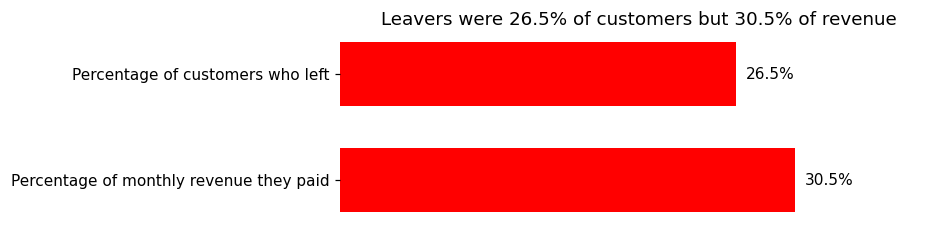

In [22]:
monthly_revenue = df['MonthlyCharges'].sum()
lost_revenue = df.loc[df['Churned'] == 1, 'MonthlyCharges'].sum()
revenue_share = lost_revenue / monthly_revenue

print(f'Monthly revenue from all customers:   ${monthly_revenue:,.0f}')
print(f'Monthly revenue from those who left:  ${lost_revenue:,.0f}  ({revenue_share:.1%} of the total)')
print(f'The same amount over 12 months:       ${lost_revenue * 12:,.0f}')
print()
print(f"Average monthly bill, stayed: ${df.loc[df['Churned'] == 0, 'MonthlyCharges'].mean():.2f}")
print(f"Average monthly bill, left:   ${df.loc[df['Churned'] == 1, 'MonthlyCharges'].mean():.2f}")

fig, ax = plt.subplots(figsize=(7, 2.2))
bars = ax.barh(['Percentage of customers who left', 'Percentage of monthly revenue they paid'], [churn_rate, revenue_share], color=LEFT, height=0.6)
ax.bar_label(bars, labels=[f'{churn_rate:.1%}', f'{revenue_share:.1%}'], padding=6)
ax.invert_yaxis()
ax.set_xlim(0, 0.4)
ax.xaxis.set_visible(False)
ax.spines[:].set_visible(False)
ax.set_title('Leavers were 26.5% of customers but 30.5% of revenue')
save('07_revenue_lost')

 **Insight:** the customers who left paid **139,131 a month**, which is **30.5% of monthly revenue**, more than their 26.5% of customers. The reason is that leavers paid more on average (**74** against **61** a month). If they are not replaced, that is about **1.67 million of revenue over a year**. The company is losing its higher-paying customers.

### 6.2 Contract and tenure together

Contract and tenure are the two strongest factors, but they are linked: new customers are usually on month-to-month contracts. This table separates them. Each cell shows the churn rate for one combination, with the number of customers below it.

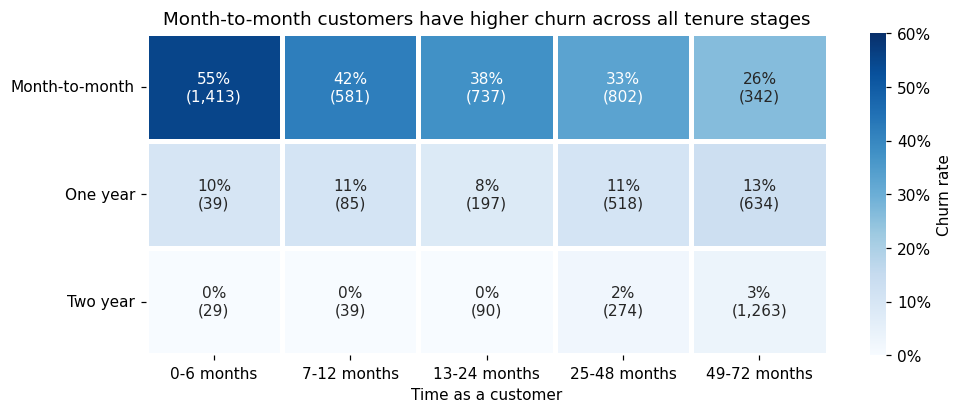

In [23]:
rate = df.pivot_table(index='Contract', columns='TenureGroup', values='Churned', aggfunc='mean', observed=False)
size = df.pivot_table(index='Contract', columns='TenureGroup', values='Churned', aggfunc='size', observed=False)
labels = rate.copy().astype(object)
for r in rate.index:
    for c in rate.columns:
        labels.loc[r, c] = f'{rate.loc[r, c]:.0%}\n({size.loc[r, c]:,})'

fig, ax = plt.subplots(figsize=(10, 3.8))
sns.heatmap(rate, annot=labels, fmt='', cmap=BLUES, vmin=0, vmax=0.6, linewidths=2, linecolor=SURFACE,
            cbar_kws={'label': 'Churn rate', 'format': PercentFormatter(1, decimals=0)}, ax=ax)
ax.set_xlabel('Time as a customer')
ax.set_ylabel('')
ax.tick_params(axis='y', rotation=0)
ax.set_title('Month-to-month customers have higher churn across all tenure stages')
save('08_contract_tenure')

 **Insight:** both factors matter on their own.
 - **Reading across a row:** within month-to-month contracts, churn falls with time, from **55%** in the first 6 months to 26% after 4 years.
 - **Reading down a column:** at every stage, month-to-month customers leave far more than contract customers. Even after 4 years, they leave at twice the rate of one-year customers (26% against 13%).
 - **Small sample sizes:** The one-year (39 customers) and two-year (29 customers) groups in the first 6 months have very few observations compared with the month-to-month group (1,413 customers). As a result, a small number of additional customers leaving can noticeably change their churn rates. For example, if 3 more two-year customers leave, the churn rate increases from 0% to approximately 10%. Therefore, percentages from these smaller groups are less stable. 

### 6.3 What does the riskiest customer look like?

Starting from all customers and adding one risk factor at a time shows how quickly the risk builds up.

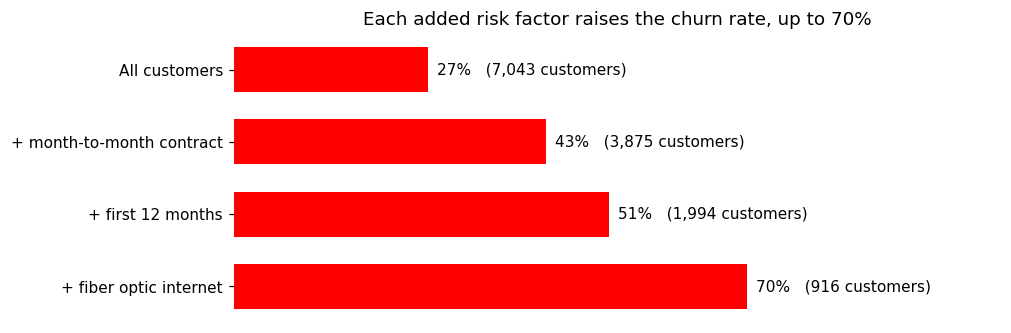

,customers,churn_rate,share_of_all_leavers
All customers,"7,043",26.5%,100.0%
+ month-to-month contract,"3,875",42.7%,88.6%
+ first 12 months,"1,994",51.4%,54.8%
+ fiber optic internet,916,70.2%,34.4%


In [24]:
month_to_month = df['Contract'] == 'Month-to-month'
first_year = df['tenure'] <= 12
fiber = df['InternetService'] == 'Fiber optic'

steps = {
    'All customers': pd.Series(True, index=df.index),
    '+ month-to-month contract': month_to_month,
    '+ first 12 months': month_to_month & first_year,
    '+ fiber optic internet': month_to_month & first_year & fiber,
}
ladder = pd.DataFrame({
    'customers': {name: mask.sum() for name, mask in steps.items()},
    'churn_rate': {name: df.loc[mask, 'Churned'].mean() for name, mask in steps.items()},
    'share_of_all_leavers': {name: df.loc[mask, 'Churned'].sum() / df['Churned'].sum() for name, mask in steps.items()},
})

fig, ax = plt.subplots(figsize=(9, 3.4))
bars = ax.barh(ladder.index, ladder['churn_rate'], color=LEFT, height=0.62)
ax.bar_label(bars, labels=[f'{r:.0%}   ({n:,} customers)' for r, n in zip(ladder['churn_rate'], ladder['customers'])], padding=6)
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
ax.xaxis.set_visible(False)
ax.spines[:].set_visible(False)
ax.set_title('Each added risk factor raises the churn rate, up to 70%')
save('09_risk_ladder')

ladder.style.format({'customers': '{:,}', 'churn_rate': '{:.1%}', 'share_of_all_leavers': '{:.1%}'})

 **Insight:**
 - **Month-to-month customers** are 55% of the base but **89% of all leavers**. Almost all churn happens here.
 - **New, month-to-month customers with fiber optic internet leave at 70%**, more than 2.5 times the average. This group is only 916 customers (13% of the base) but produces **34% of all leavers**.
 - Churn is **concentrated**, which is good news: a retention budget aimed at the right customers can reach a large share of the problem.

In [25]:
# Segment tables for anyone who wants the numbers behind the charts
segment_table = pd.concat({c: get_churn_rates(c) for c in category_columns + ['TenureGroup'] if c != 'Churn'}, names=['column', 'group'])
segment_table.round(4).to_csv(OUT_DIR / 'churn_rate_by_segment.csv')
segment_table.head(8).style.format({'churn_rate': '{:.1%}', 'customers': '{:,}'})

## 7. Solution, part 1: a model that scores churn risk

The retention team needs something more practical: a **risk score for each customer**, so they can start with the customers most likely to leave. A model can do this by combining all the factors at once.

**Approach**

- **Model:** logistic regression. It is simple, fast and each factor's effect can be read directly, which makes it easy to explain to the business. I compare it with a more complex model (random forest) to check that the simple choice does not cost accuracy.
- **Fair test:** the model learns from 75% of customers (training set) and is tested on the other 25% that it has never seen (test set).
- **Features:** all customer details except `customerID` (just a label) and `TotalCharges` (repeats tenure, see 5.5).

### 7.1 Preparing the data

In [26]:
NUM_FEATURES = ['tenure', 'MonthlyCharges']
CAT_FEATURES = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
                'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
                'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
FEATURES = NUM_FEATURES + CAT_FEATURES

# "No internet service" / "No phone service" simply mean the customer does not have the add-on.
# The InternetService and PhoneService columns already say why, so I simplify these labels to "No".
model_data = df[FEATURES].replace({'No internet service': 'No', 'No phone service': 'No'})
target = df['Churned']

X_train, X_test, y_train, y_test = train_test_split(
    model_data, target, test_size=0.25, stratify=target, random_state=SEED)

print(f'Training set: {len(X_train):,} customers, churn rate {y_train.mean():.1%}')
print(f'Test set:     {len(X_test):,} customers, churn rate {y_test.mean():.1%}')

Training set: 5,282 customers, churn rate 26.5%
Test set:     1,761 customers, churn rate 26.5%


The split is *stratified*, which keeps the churn rate the same in both sets.

Models need numbers, so the preparation step puts the numeric columns on the same scale and turns each category into 0/1 columns (one-hot encoding). Wrapping the steps in a **pipeline** means they are learned from the training data only, so nothing leaks from the test set.

### 7.2 Compare a simple and a complex model

Each model is trained and scored 5 times on different slices of the training data (5-fold cross-validation). The score is **AUC**: 0.5 means the model is guessing, 1.0 means it ranks every leaver above every stayer.

In [27]:
def make_model(estimator):
    prepare = ColumnTransformer([
        ('num', StandardScaler(), NUM_FEATURES),
        ('cat', OneHotEncoder(drop='if_binary'), CAT_FEATURES),
    ])
    return make_pipeline(prepare, estimator)


candidates = {
    'Logistic regression (simple)': LogisticRegression(max_iter=1000),
    'Random forest (complex)': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED),
}
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

comparison = pd.DataFrame({
    name: cross_val_score(make_model(estimator), X_train, y_train, cv=folds, scoring='roc_auc')
    for name, estimator in candidates.items()
}).agg(['mean', 'std']).T.rename(columns={'mean': 'Average AUC', 'std': 'Spread between folds'})
comparison.round(3)

,Average AUC,Spread between folds
Logistic regression (simple),0.843,0.017
Random forest (complex),0.843,0.015


 **Insight:** the two models score almost the same (about **0.843** and **0.843**), and the gap is no bigger than the spread between folds. The complex model is not better, so I keep **logistic regression**, because every score it gives can be explained.

### 7.3 Final test on customers the model has never seen

In [28]:
model = make_model(LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

risk = pd.Series(model.predict_proba(X_test)[:, 1], index=X_test.index, name='risk')
predicted = (risk >= 0.5).astype(int)   # default rule: flag a customer if the risk is 50% or more

auc = roc_auc_score(y_test, risk)
print(f'AUC on the test set: {auc:.3f}')
print(f'Accuracy:  {(predicted == y_test).mean():.1%}   (always saying "stays" would score {1 - y_test.mean():.1%})')
print(f'Precision: {precision_score(y_test, predicted):.1%}   of the customers flagged, this share really left')
print(f'Recall:    {recall_score(y_test, predicted):.1%}   of the customers who left, this share was flagged')

matrix = pd.DataFrame(confusion_matrix(y_test, predicted),
                      index=['Actually stayed', 'Actually left'], columns=['Predicted to stay', 'Predicted to leave'])
matrix

AUC on the test set: 0.845
Accuracy:  80.1%   (always saying "stays" would score 73.5%)
Precision: 64.7%   of the customers flagged, this share really left
Recall:    55.0%   of the customers who left, this share was flagged


,Predicted to stay,Predicted to leave
Actually stayed,1154,140
Actually left,210,257


 **Insight:** the test AUC of **0.845** is close to the cross-validation score, so the model works just as well on new customers. With the default 50% cut-off it flags 397 customers, of whom 65% really left and it catches 55% of all leavers.

 Accuracy (80.1%) is only a little above the 73.5% (by predicting that nobody leaves), which is why accuracy is the wrong measure here. A fixed 50% cut-off is also not how the model would be used. The retention team works down a **ranked list**, so the useful question is: *if we contact the top X% of customers by risk, how many leavers do we reach?*

### 7.4 How many leavers does the model reach?

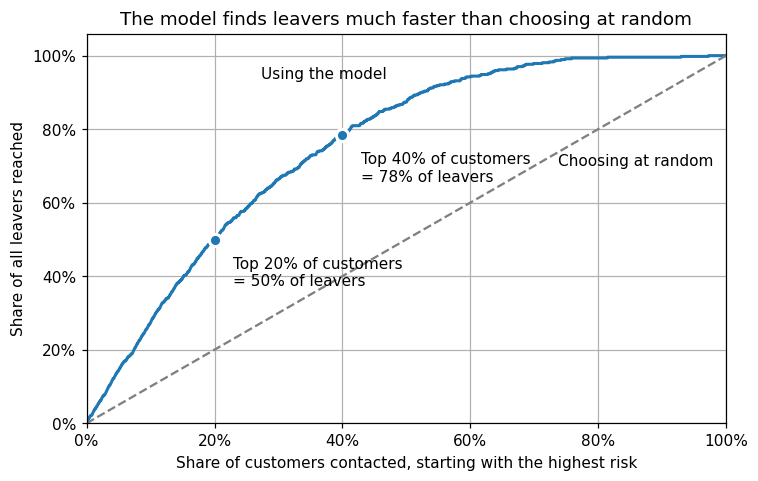

Customers contacted (top % by risk),Leavers reached with the model,Leavers reached at random,Times better than random
10%,27%,10%,2.7x
20%,50%,20%,2.5x
30%,66%,30%,2.2x
40%,78%,40%,2.0x
50%,87%,50%,1.7x


In [29]:
ranked = pd.DataFrame({'risk': risk, 'left': y_test}).sort_values('risk', ascending=False)
ranked['share_contacted'] = np.arange(1, len(ranked) + 1) / len(ranked)
ranked['share_of_leavers_reached'] = ranked['left'].cumsum() / ranked['left'].sum()

reach = pd.DataFrame({'Customers contacted (top % by risk)': [0.1, 0.2, 0.3, 0.4, 0.5]})
reach['Leavers reached with the model'] = [ranked.loc[ranked['share_contacted'] <= s, 'share_of_leavers_reached'].iloc[-1]
                                           for s in reach.iloc[:, 0]]
reach['Leavers reached at random'] = reach.iloc[:, 0]
reach['Times better than random'] = reach['Leavers reached with the model'] / reach['Leavers reached at random']

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.plot(ranked['share_contacted'], ranked['share_of_leavers_reached'], color=STAYED, linewidth=2)
ax.plot([0, 1], [0, 1], color=GREY, linestyle='--', linewidth=1.5)
for share in (0.2, 0.4):
    reached = reach.loc[reach.iloc[:, 0] == share, 'Leavers reached with the model'].iloc[0]
    ax.scatter(share, reached, s=64, color=STAYED, edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.annotate(f'Top {share:.0%} of customers\n= {reached:.0%} of leavers', (share, reached), xytext=(12, -30),
                textcoords='offset points', color=INK, fontsize=10)
ax.text(0.47, 0.93, 'Using the model', color=INK, ha='right', va='bottom', fontsize=10)
ax.text(0.98, 0.70, 'Choosing at random', color=INK_2, ha='right', fontsize=10)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.06)
ax.grid(True)
ax.set_xlabel('Share of customers contacted, starting with the highest risk')
ax.set_ylabel('Share of all leavers reached')
ax.set_title('The model finds leavers much faster than choosing at random')
save('10_model_reach')

reach.style.format({c: '{:.0%}' for c in reach.columns[:3]} | {'Times better than random': '{:.1f}x'}).hide(axis='index')

 **Insight:** contacting the **top 20%** of customers by risk score reaches **50% of all leavers**, which is **2.5 times** better than picking customers at random. The top 40% reaches 78%. The retention team can cover most of the problem by contacting a minority of customers.

### 7.5 Can the scores be read as real percentages?

In section 8 the risk score is multiplied by money, so it has to be honest: of the customers scored around 60%, about 60% should really leave. To check, I sort the test customers into 10 equal groups by score and compare the average score with the share who actually left.

### Model calibration analysis

When for example, model says customers have a 30% chance of leaving, do approximately 30% of those customers actually leave?

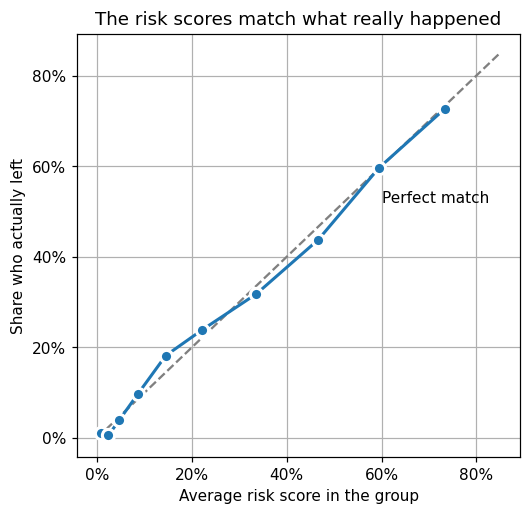

,average_risk_score,actually_left,customers
group,,,
1,1%,1%,177
2,2%,1%,176
3,5%,4%,176
4,9%,10%,176
5,14%,18%,176
6,22%,24%,176
7,34%,32%,176
8,47%,44%,176
9,59%,60%,176


In [30]:
check = pd.DataFrame({'risk': risk, 'left': y_test})
check['group'] = pd.qcut(check['risk'], 10, labels=range(1, 11))
calibration = check.groupby('group', observed=True).agg(average_risk_score=('risk', 'mean'), actually_left=('left', 'mean'), customers=('left', 'size'))

fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([0, 0.85], [0, 0.85], color=GREY, linestyle='--', linewidth=1.5)
ax.plot(calibration['average_risk_score'], calibration['actually_left'], color=STAYED, linewidth=2, marker='o',
        markersize=8, markeredgecolor=SURFACE, markeredgewidth=2)
ax.text(0.60, 0.52, 'Perfect match', color=INK_2, fontsize=10)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(True)
ax.set_xlabel('Average risk score in the group')
ax.set_ylabel('Share who actually left')
ax.set_title('The risk scores match what really happened')
save('11_score_check')

calibration.style.format({'average_risk_score': '{:.0%}', 'actually_left': '{:.0%}'})

 **Insight:** the points sit close to the dashed line, so the scores can be read as real probabilities. A group scored around 73% really did lose about 73% of its customers.

### 7.6 What did the model learn?

Each bar is one factor. Bars to the right **raise** the risk score and bars to the left **lower** it, with everything else held equal. The numeric columns are scaled, so the sizes can be compared.

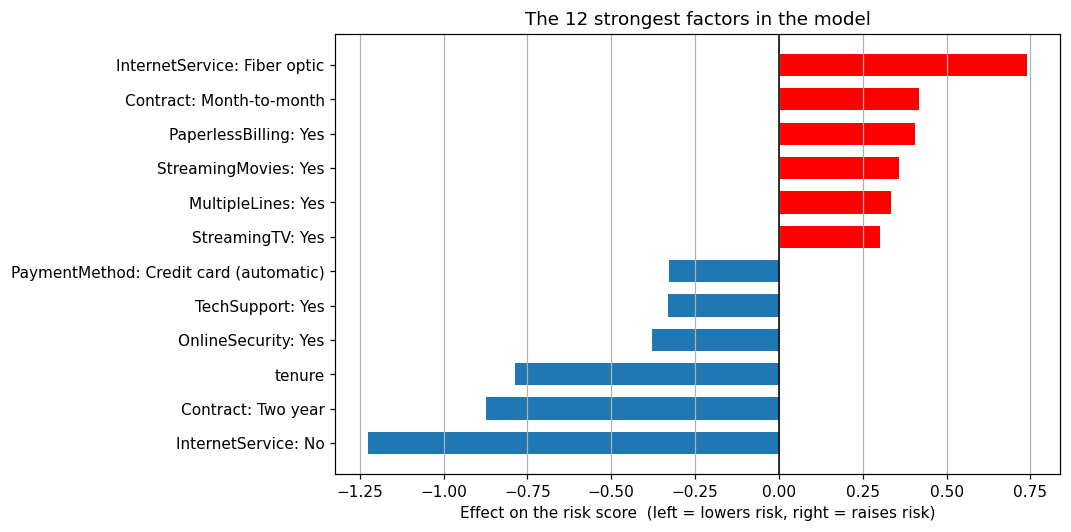

In [31]:
names = model[0].get_feature_names_out()
names = [n.split('__')[1].replace('_', ': ', 1) for n in names]
effects = pd.Series(model[-1].coef_[0], index=names)
top = effects.reindex(effects.abs().sort_values(ascending=False).index).head(12).sort_values()

fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.barh(top.index, top.values, color=[LEFT if v > 0 else STAYED for v in top.values], height=0.65)
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('Effect on the risk score  (left = lowers risk, right = raises risk)')
ax.grid(axis='x')
ax.set_title('The 12 strongest factors in the model')
save('12_model_factors')

 **Insight:** the model agrees with the EDA, which is a good sign.
 - **Raises risk:** fiber optic internet is the strongest risk factor, followed by a month-to-month contract and paperless billing.
 - **Lowers risk:** having no internet service, a two-year contract and a long tenure are the strongest protective factors. Online security, tech support and automatic card payment also lower risk.
 - Streaming services and multiple phone lines appear as smaller risk factors. These columns are linked to each other and to the monthly bill, so their individual effects should be read with more care than the big ones.

 These are patterns in the data, not proof of cause. For example, the model cannot tell whether a two-year contract makes people stay or whether people who already planned to stay choose two-year contracts.

## 8. Solution, part 2: a retention campaign that pays for itself

A risk score is only useful if it leads to a decision. This section turns the scores into a plan: **who should get a retention offer and what would it earn?**

### 8.1 Assumptions

The dataset has no information about retention offers, so three numbers have to be assumed. They are written as variables so that anyone can change them and re-run the section.

| Assumption | Value | Meaning |
|---|---|---|
| `OFFER_COST` | \$60 | Cost of one offer (for example a discount plus the call), paid for **every** customer who gets it |
| `SUCCESS_RATE` | 30% | Percentage of customers who would have left but decide to stay after receiving the offer.|
| `MONTHS_KEPT` | 12 | Number of additional months a retained customer is expected to remain with the company and pay their monthly bill. |

**The decision rule.** Send the offer only when it is expected to earn more than it costs:

expected gain = risk score × success rate × monthly bill × months kept > offer cost


Example: a customer with a 50% risk score and an 80 bill has an expected gain of 0.50 × 0.30 × 80 × 12 = 144. That is more than 60, so they get the offer.

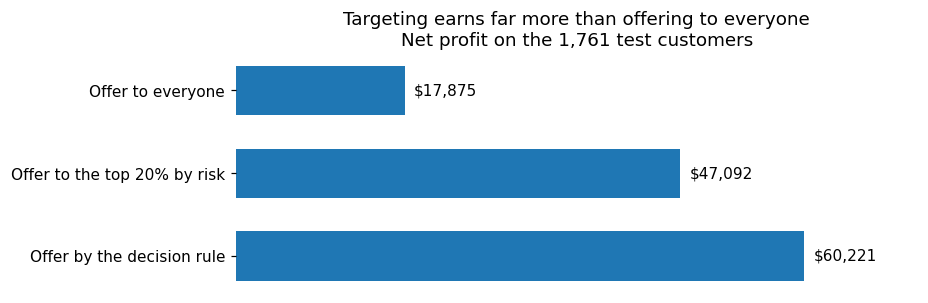

,Customers contacted,Share of customers,Leavers reached,Campaign cost,Net profit
Offer to everyone,"1,761",100%,100%,"$105,660","$17,875"
Offer to the top 20% by risk,353,20%,50%,"$21,180","$47,092"
Offer by the decision rule,704,40%,75%,"$42,240","$60,221"


In [32]:
OFFER_COST = 60       # $ per customer who gets the offer
SUCCESS_RATE = 0.30   # share of would-be leavers the offer keeps
MONTHS_KEPT = 12      # extra months a saved customer stays

test = df.loc[X_test.index, ['customerID', 'Contract', 'tenure', 'InternetService', 'MonthlyCharges', 'Churned']].copy()
test['risk'] = risk
test['value_if_saved'] = test['MonthlyCharges'] * MONTHS_KEPT
test['expected_gain'] = test['risk'] * SUCCESS_RATE * test['value_if_saved']
test['send_offer'] = test['expected_gain'] > OFFER_COST


def campaign_profit(selected, success_rate=SUCCESS_RATE, offer_cost=OFFER_COST):
    # Profit of sending the offer to the selected customers, using who REALLY left.
    # Only customers who were going to leave can be saved. Everyone selected costs one offer.
    revenue_saved = (test.loc[selected, 'Churned'] * success_rate * test.loc[selected, 'value_if_saved']).sum()
    return revenue_saved - offer_cost * selected.sum()


top_20 = test['risk'] >= test['risk'].quantile(0.80)
plans = {
    'Offer to everyone': pd.Series(True, index=test.index),
    'Offer to the top 20% by risk': top_20,
    'Offer by the decision rule': test['send_offer'],
}
results = pd.DataFrame({
    'Customers contacted': {name: selected.sum() for name, selected in plans.items()},
    'Share of customers': {name: selected.mean() for name, selected in plans.items()},
    'Leavers reached': {name: test.loc[selected, 'Churned'].sum() / test['Churned'].sum() for name, selected in plans.items()},
    'Campaign cost': {name: OFFER_COST * selected.sum() for name, selected in plans.items()},
    'Net profit': {name: campaign_profit(selected) for name, selected in plans.items()},
})

fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(results.index, results['Net profit'], color=STAYED, height=0.6)
ax.bar_label(bars, labels=[f'${v:,.0f}' for v in results['Net profit']], padding=6)
ax.invert_yaxis()
ax.set_xlim(0, results['Net profit'].max() * 1.2)
ax.xaxis.set_visible(False)
ax.spines[:].set_visible(False)
ax.set_title(f'Targeting earns far more than offering to everyone\nNet profit on the {len(test):,} test customers')
save('13_campaign_profit')

results.to_csv(OUT_DIR / 'campaign_plans.csv')
results.style.format({'Customers contacted': '{:,}', 'Share of customers': '{:.0%}', 'Leavers reached': '{:.0%}',
                      'Campaign cost': '${:,.0f}', 'Net profit': '${:,.0f}'})

 **Insight:**
 - **Offering to everyone** makes only **\$17,875**, because most of the budget goes to customers who were never going to leave.
 - **The decision rule** contacts 40% of customers, reaches 75% of the leavers and earns **\$60,221**, about **3.4 times** the profit at 40% of the cost.
 - These figures are for the 1,761 test customers only (a quarter of the base). Applied to the full customer base, the amounts would be roughly four times larger.

### 8.2 Three risk tiers for the retention team

A score is easier to act on as a tier with a suggested action.

In [33]:
test['risk_tier'] = pd.cut(test['risk'], bins=[0, 0.20, 0.50, 1], labels=['Low (under 20%)', 'Medium (20-50%)', 'High (over 50%)'])

tiers = test.groupby('risk_tier', observed=True).agg(
    customers=('Churned', 'size'),
    actually_left=('Churned', 'mean'),
    average_monthly_bill=('MonthlyCharges', 'mean'),
    share_getting_offer=('send_offer', 'mean'),
)
tiers['suggested_action'] = ['No offer. Keep service quality high',
                             'Low-cost contact: check-in email, contract upgrade offer',
                             'Priority: personal call with the retention offer']
tiers.style.format({'customers': '{:,}', 'actually_left': '{:.0%}', 'average_monthly_bill': '${:.0f}', 'share_getting_offer': '{:.0%}'})

,customers,actually_left,average_monthly_bill,share_getting_offer,suggested_action
risk_tier,,,,,
Low (under 20%),921,7%,$55,2%,No offer. Keep service quality high
Medium (20-50%),443,33%,$68,67%,"Low-cost contact: check-in email, contract upgrade offer"
High (over 50%),397,65%,$82,98%,Priority: personal call with the retention offer


 **Insight:** the tiers separate customers well. In the **High** tier about **65%** really left, against **32%** in Medium and only **7%** in Low. The retention team should start with the High tier and leave the Low tier alone.

### 8.3 What if the assumptions are wrong?

The offer cost and the success rate are the weakest part of this calculation, because they are assumed and not measured. The tables below repeat the profit calculation for 15 combinations. Blue cells make money, red cells lose money.

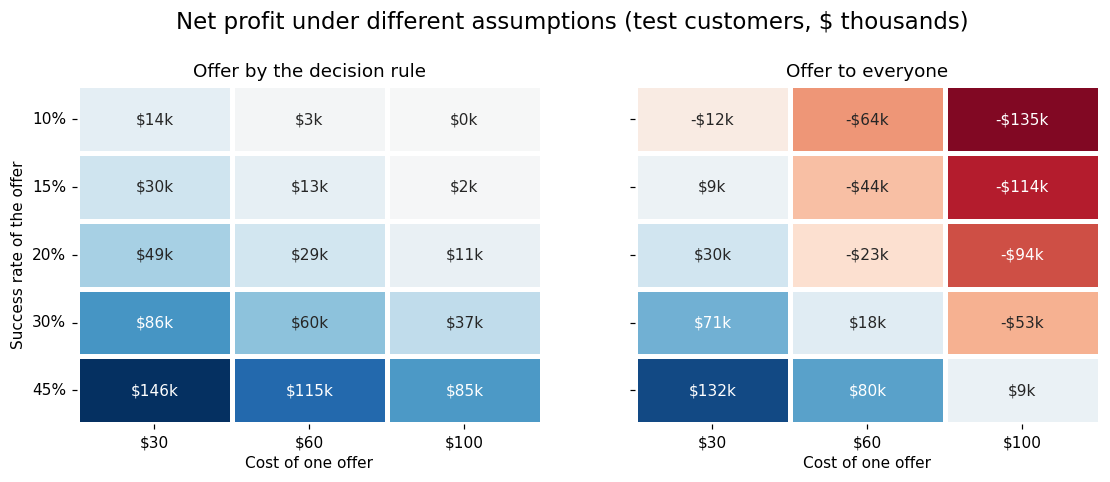

Scenarios where the decision rule loses money:   0 of 15
Scenarios where offering to everyone loses money: 8 of 15


In [34]:
success_rates = [0.10, 0.15, 0.20, 0.30, 0.45]
offer_costs = [30, 60, 100]

rule_profit = pd.DataFrame(index=[f'{s:.0%}' for s in success_rates], columns=[f'${c}' for c in offer_costs], dtype=float)
everyone_profit = rule_profit.copy()
for s in success_rates:
    for c in offer_costs:
        selected = test['risk'] * s * test['value_if_saved'] > c      # the decision rule under these assumptions
        rule_profit.loc[f'{s:.0%}', f'${c}'] = campaign_profit(selected, s, c)
        everyone_profit.loc[f'{s:.0%}', f'${c}'] = campaign_profit(pd.Series(True, index=test.index), s, c)

limit = max(abs(everyone_profit.values).max(), abs(rule_profit.values).max())
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, table, title in [(axes[0], rule_profit, 'Offer by the decision rule'), (axes[1], everyone_profit, 'Offer to everyone')]:
    labels = table.apply(lambda column: column.map(lambda v: f"{'-' if v < 0 else ''}${abs(v) / 1000:,.0f}k"))
    sns.heatmap(table, annot=labels, fmt='', cmap=DIVERGING, vmin=-limit, vmax=limit, center=0, cbar=False,
                linewidths=2, linecolor=SURFACE, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Cost of one offer')
    ax.tick_params(axis='y', rotation=0)
axes[0].set_ylabel('Success rate of the offer')
fig.suptitle('Net profit under different assumptions (test customers, $ thousands)', fontsize=15, y=1.05)
save('14_sensitivity')

pd.concat({'Decision rule': rule_profit, 'Everyone': everyone_profit}, axis=1).round(0).to_csv(OUT_DIR / 'profit_sensitivity.csv')
print(f'Scenarios where the decision rule loses money:   {(rule_profit < 0).sum().sum()} of {rule_profit.size}')
print(f'Scenarios where offering to everyone loses money: {(everyone_profit < 0).sum().sum()} of {everyone_profit.size}')

 **Insight:** the targeted plan is the safer choice. **Offering to everyone loses money in 8 of the 15 scenarios**, while **the decision rule never loses money**. When the offer is expensive or works poorly, the rule simply contacts fewer customers. The size of the profit still depends heavily on the success rate, so that number should be measured with a real test before a full launch.

### 8.4 The list for the retention team

The final output is a file the retention team could work from: one row per customer, highest risk first.

In [35]:
target_list = (test.sort_values('risk', ascending=False)
               [['customerID', 'risk', 'risk_tier', 'send_offer', 'expected_gain', 'MonthlyCharges', 'tenure', 'Contract', 'InternetService']]
               .round({'risk': 3, 'expected_gain': 2}))
target_list.to_csv(OUT_DIR / 'retention_target_list.csv', index=False)

print(f'{len(target_list):,} customers saved to outputs/retention_target_list.csv')
target_list.head(10)

1,761 customers saved to outputs/retention_target_list.csv


,customerID,risk,risk_tier,send_offer,expected_gain,MonthlyCharges,tenure,Contract,InternetService
3380,5178-LMXOP,0.868,High (over 50%),True,297.03,95.10,1,Month-to-month,Fiber optic
6866,0295-PPHDO,0.846,High (over 50%),True,290.58,95.45,1,Month-to-month,Fiber optic
2631,6861-XWTWQ,0.843,High (over 50%),True,301.36,99.25,7,Month-to-month,Fiber optic
6365,8884-ADFVN,0.842,High (over 50%),True,308.97,101.95,7,Month-to-month,Fiber optic
6894,1400-MMYXY,0.841,High (over 50%),True,320.61,105.90,3,Month-to-month,Fiber optic
2797,6023-YEBUP,0.836,High (over 50%),True,303.74,100.95,3,Month-to-month,Fiber optic
3727,9057-SIHCH,0.836,High (over 50%),True,290.62,96.60,3,Month-to-month,Fiber optic
4585,1069-XAIEM,0.835,High (over 50%),True,255.71,85.05,1,Month-to-month,Fiber optic
3346,2545-EBUPK,0.831,High (over 50%),True,251.55,84.05,2,Month-to-month,Fiber optic
4517,2012-NWRPA,0.825,High (over 50%),True,295.60,99.55,11,Month-to-month,Fiber optic


In this project, the model is evaluated using test customers whose actual churn outcomes are already known. This allows us to check how accurately it identifies customers who leave. In a real business setting, the model would instead be applied to all active customers each month to identify those at risk of leaving.

In [36]:
# All the key numbers in one place, calculated from the data above
rule = results.loc['Offer by the decision rule']
summary = pd.Series({
    'Customers': f'{len(df):,}',
    'Left in the last month': f"{df['Churned'].sum():,} ({churn_rate:.1%})",
    'Monthly revenue they paid': f'${lost_revenue:,.0f} ({revenue_share:.1%} of revenue)',
    'Same amount over 12 months': f'${lost_revenue * 12:,.0f}',
    'Churn rate, month-to-month contract': f"{df.loc[month_to_month, 'Churned'].mean():.1%}",
    'Churn rate, two-year contract': f"{df.loc[df['Contract'] == 'Two year', 'Churned'].mean():.1%}",
    'Churn rate, riskiest segment': f"{ladder['churn_rate'].iloc[-1]:.1%}",
    'Model AUC (test set)': f'{auc:.3f}',
    'Leavers reached in the top 20% by risk': f"{reach.iloc[1, 1]:.0%}",
    'Decision rule: customers contacted': f"{rule['Customers contacted']:,.0f} ({rule['Share of customers']:.0%})",
    'Decision rule: net profit (test set)': f"${rule['Net profit']:,.0f}",
    'Offer to everyone: net profit (test set)': f"${results.loc['Offer to everyone', 'Net profit']:,.0f}",
}, name='Value')
summary.to_frame()

,Value
Customers,"7,043"
Left in the last month,"1,869 (26.5%)"
Monthly revenue they paid,"$139,131 (30.5% of revenue)"
Same amount over 12 months,"$1,669,570"
"Churn rate, month-to-month contract",42.7%
"Churn rate, two-year contract",2.8%
"Churn rate, riskiest segment",70.2%
Model AUC (test set),0.845
Leavers reached in the top 20% by risk,50%
Decision rule: customers contacted,704 (40%)


## 9. Recommendations

| # | Recommendation | Evidence from this analysis | How to measure it |
|---|---|---|---|
| 1 | **Run a targeted retention campaign** using the risk score and the decision rule, starting with the High tier. | Targeting earns about 3.4 times the profit of offering to everyone, at 40% of the cost (8.1). | Churn rate of contacted customers against a control group that gets no offer |
| 2 | **Test the offer on a small group first** (an A/B test). | The profit depends on the success rate, which is assumed here, not measured (8.3). | Real success rate and cost per saved customer |
| 3 | **Improve the first 6 to 12 months**: welcome call, setup help, a check-in after the first bills. | 53% of customers in their first 6 months left, against 10% after 4 years (5.4). | Churn rate in the first 6 months |
| 4 | **Move month-to-month customers to longer contracts**, for example with a discount for a one-year plan. | Month-to-month customers are 89% of all leavers and leave at 43%, against 11% on one-year contracts (5.3, 6.3). | Share of customers on one-year and two-year contracts |
| 5 | **Find out why fiber optic customers leave.** Check price, reliability and competitor offers. | Fiber customers leave at 42%, more than twice the DSL rate, and they pay the highest bills (5.3). | Fiber churn rate, complaints and exit-survey answers |
| 6 | **Promote tech support and online security**, for example as a free trial for new customers. | Customers without them leave at about 42%, against 15% with them (5.3). | Add-on take-up, and churn of trial users against non-users |
| 7 | **Encourage automatic payment** in place of electronic check. | Electronic check customers leave at 45%, against 15 to 19% for the other methods (5.3). | Share of customers on automatic payment |

Recommendations 4 to 7 are based on patterns in the data, which show a link but not a cause. Each one should be tried on a small group before it is rolled out to everyone.

## 10. Limitations and next steps

**Limitations**

- **Sample data.** This is IBM's fictional sample dataset. The numbers show the method, not a real company's results.
- **One snapshot.** The data shows one moment in time. There is no history of how a customer's behavior changed before leaving and no information on *why* they left (price, service problems, moving home).
- **Assumed campaign numbers.** The offer cost (\$60), success rate (30%) and months kept (12) are assumptions. Section 8.3 shows how much the result depends on them.
- **Correlation, not cause.** The analysis shows which customers leave more often. It cannot prove that changing a factor (for example the contract type) would make a customer stay.
- **Who will leave is not the same as who can be saved.** The model predicts who is likely to leave. Some of those customers would leave whatever the offer is and some would stay without one.
- **Profit is measured on the test set.** The dollar figures are for 1,761 customers and are an estimate, not a forecast.

**Next steps**

1. Run an A/B test of the retention offer to measure the real success rate.
2. Add data on complaints, support calls and usage, which usually signal churn early.
3. Collect several months of history to see how risk changes over time.
4. Run an exit survey to learn the reasons behind fiber optic churn.